# MTM shape check: are the $A_\parallel$ spike trains of bhx7.17 real, or a pipeline artefact?

Fusion_PhD-bhx7.19. The user (2026-11-17), on `apar_bands_eigenfunctions.png`: "I think there must be something off with the mtm shape
detection and mtm should look like this" (a published GS2 linear MTM, $k_y\rho_s=0.14$: $\phi$ odd with a sharp jump at $\theta=0$ on a
broad envelope; $A_\parallel$ even, ONE dominant spike at $\theta=0$, small spikes near $\pm2.5\pi,\pm5\pi$).

Per sample, two sources in ballooning $\theta$ (never $\theta_b$) in the user's format (Re blue, Im orange, $\phi/\max|\phi|$ over the full
box, $A_\parallel/\max|\phi|$ over $\pm10\pi$):
- (a) the GS2 run's own final-time complex field: `scan.sample_pyro(name)` then `pyro.load_gk_output(path=<run>/gs2.out.nc)`;
- (b) the cube field exactly as bhx7.17 read it: `PyroHypercube.load_gk_output(cube.nc)`, `phi`/`apar`.
The cube is read through the scan; the run is read per run because the cube holds one time slice per sample, not the history (the one
exception to the cube rule). The phase is rotated so $\phi$ is real at its peak, the same rotation on both fields.

In [1]:
import os
from multiprocessing import get_context
from pathlib import Path
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from pyrokinetics import Pyro, PyroHypercube
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.diagnostics.field_line import FieldLine
from general_analysis import mode_classification as mc

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
data_root = Path(os.path.expandvars(os.environ["GK_DATA_ROOT"]))     # the WORK tree
plots_dir = ROOT / "Plots" / "mtm_shape_check"
plots_dir.mkdir(parents=True, exist_ok=True)
n_cpu = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))

draws = {"n1000": "beta_q_shat_ky_n1000", "n300": "beta_q_shat_ky_n300"}
fields = ["phi", "apar"]
named = ["iteration_114", "iteration_175", "iteration_77", "iteration_286", "iteration_398", "iteration_237"]   # apar_bands_eigenfunctions.png, n1000
analytic_even = 2.772            # bhx7.17: $W_{A_\parallel}=E^{\theta_b}_{A_\parallel}/2.772$
band_edges = [0, 3, 8, 12.5, 17.5, 25, np.inf]
tolerance_gate = 1e-2


def extent_95(power, coordinate):
    keep = np.isfinite(power)
    return float(Extent._compute(xr.DataArray(power[keep][None], dims=("sample", "theta"), coords=dict(theta=coordinate[keep])), 0.95)[0][0])


def load_gs2(draw):
    cube_dir = data_root / "GS2/Runs/LATIN_HYPERCUBE/NSTX_MTM" / draws[draw] / "pyro_cube_avg"
    scan = PyroHypercube(pyro=Pyro(gk_file=cube_dir / "pyroscan_base.input", gk_code="GS2"), pyroscan_json=cube_dir / "pyroscan.json",
                         base_directory=cube_dir.parent, file_name="gs2.in")
    scan.load_gk_output(netcdf_file=cube_dir / "cube.nc")
    return scan


gs2_scans = {draw: load_gs2(draw) for draw in draws}

## Population table (the bhx7.17 MTM selection and its $A_\parallel$ width), plus the spike count of the cube field in $\theta$
MTM: $T>0.15$, $\omega<0$, $\gamma>0$, tolerance $<0.01$. A spike is a local maximum of $|A_\parallel|/\max|A_\parallel|$ above 0.3 within
$|\theta|<10\pi$ (prominence 0.1). `spike_count` and `spike_offset` (the distance of a spike from the nearest $2\pi p$, in units of $\pi$)
need no $\theta_b$: a monotonic relabelling cannot create or remove a local maximum.

In [2]:
def spikes(amplitude, theta):
    window = abs(theta) < 10 * np.pi
    peak_index, _ = find_peaks(amplitude[window] / amplitude[window].max(), height=0.3, prominence=0.1)
    position = theta[window][peak_index] / np.pi
    return position, np.abs(position - 2 * np.round(position / 2))


def population_row(args):
    draw, i = args
    scan = gs2_scans[draw]
    output = scan.gk_output.data.isel(sample=i)
    finite_theta = output.apar.pint.dequantify().dropna("theta").sortby("theta").theta
    fields_theta = {field: output[field].pint.dequantify().sel(theta=finite_theta) for field in fields}
    field_line = FieldLine(scan.sample_pyro(i, gk_output=xr.Dataset(fields_theta)))
    theta = fields_theta["apar"].theta.values
    basis_angle = field_line.compute_basis_angle(theta)
    apar_amplitude = np.abs(fields_theta["apar"].values)
    position, offset = spikes(apar_amplitude, theta)
    return dict(draw=draw, sample=str(output.sample_name.values), ky=float(output.ky), shat=float(output.shat), q=float(output.q),
                beta=float(output.beta), gamma=float(output.growth_rate.pint.dequantify()),
                omega=mc.ION_DIRECTION * float(output.mode_frequency.pint.dequantify()),
                tolerance=float(output.growth_rate_tolerance.pint.dequantify()),
                T=float(field_line.compute_linear_tearing_parameter().squeeze()),
                apar_width=extent_95(apar_amplitude ** 2, basis_angle) / analytic_even,
                spike_count=len(position), spike_offset_median=float(np.median(offset)) if len(offset) else np.nan,
                spike_offset_max=float(offset.max()) if len(offset) else np.nan)


with get_context("fork").Pool(n_cpu) as pool:
    population = pd.DataFrame(pool.map(population_row, [(draw, i) for draw in draws for i in range(gs2_scans[draw].gk_output.data.sizes["sample"])], chunksize=8))
population["label"] = mc.classify_T_omega(population)
mtm = population[(population.label == "MTM") & (population.gamma > 0) & (population.tolerance < tolerance_gate)].copy()
mtm["apar_band"] = pd.cut(mtm.apar_width, band_edges)
mtm["ky_shat"] = mtm.ky * mtm.shat
print(len(mtm), "MTMs;", (mtm.draw == "n1000").sum(), "n1000")
print(mtm.groupby("apar_band", observed=True).agg(n=("sample", "size"), spikes_median=("spike_count", "median"), ky_median=("ky", "median"),
                                                 shat_median=("shat", "median"), ky_shat_median=("ky_shat", "median")).round(3).to_string())

885 MTMs; 683 n1000
                n  spikes_median  ky_median  shat_median  ky_shat_median
apar_band                                                               
(0.0, 3.0]    386            1.0      0.425        2.285           0.807
(3.0, 8.0]    222            3.0      0.237        1.474           0.327
(8.0, 12.5]   107            5.0      0.188        0.965           0.161
(12.5, 17.5]   63            9.0      0.139        0.690           0.098
(17.5, 25.0]   54           13.0      0.107        0.522           0.060
(25.0, inf]    53           15.0      0.081        0.246           0.023


## The samples
The six of `apar_bands_eigenfunctions.png`; one median-$\gamma$ MTM from each $W_{A_\parallel}$ band, alternating n1000 / n300 (the first band
not already covered); and the two lowest-$k_y$ MTMs with $0.8<\hat s<1.5$, the regime of the user's figure ($k_y\rho_s=0.14$).

In [3]:
chosen = [("n1000", name) for name in named]
for number, (_, rows) in enumerate(mtm.groupby("apar_band", observed=True)):
    draw = ("n1000", "n300")[number % 2]
    pool_rows = rows[rows.draw == draw]
    if len(pool_rows) and not (pool_rows["sample"].isin(named) & (pool_rows.draw == "n1000")).all():
        pool_rows = pool_rows[~((pool_rows.draw == "n1000") & pool_rows["sample"].isin(named))]
        chosen.append((draw, pool_rows.iloc[(pool_rows.gamma - pool_rows.gamma.median()).abs().argmin()]["sample"]))
low_ky = mtm[(mtm.shat > 0.8) & (mtm.shat < 1.5)].nsmallest(2, "ky")
chosen += [(row.draw, row["sample"]) for _, row in low_ky.iterrows() if (row.draw, row["sample"]) not in chosen]
print(chosen)

[('n1000', 'iteration_114'), ('n1000', 'iteration_175'), ('n1000', 'iteration_77'), ('n1000', 'iteration_286'), ('n1000', 'iteration_398'), ('n1000', 'iteration_237'), ('n1000', 'iteration_548'), ('n300', 'iteration_158'), ('n1000', 'iteration_76'), ('n300', 'iteration_230'), ('n1000', 'iteration_180'), ('n300', 'iteration_46'), ('n1000', 'iteration_295'), ('n1000', 'iteration_405')]


## Per-sample: run final-time field, cube field, tail average, $\theta$ vs $\theta_b$

In [4]:
def rotated(values, reference_amplitude):
    # phase so phi is real at its peak; the same factor for both fields
    return values * np.conj(reference_amplitude) / abs(reference_amplitude)


def inspect(spec):
    draw, name = spec
    scan = gs2_scans[draw]
    cube = scan.gk_output.data.set_index(sample="sample_name").sel(sample=name)
    finite_theta = cube.apar.pint.dequantify().dropna("theta").sortby("theta").theta
    theta_cube = finite_theta.values
    pyro = scan.sample_pyro(name)
    pyro.load_gk_output(path=data_root / "GS2/Runs/LATIN_HYPERCUBE/NSTX_MTM" / draws[draw] / name / "gs2.out.nc")
    run = pyro.gk_output
    run_theta = run["phi"].theta.values
    theta = run_theta
    print(name, "run theta points", len(run_theta), "cube finite points", len(theta_cube), "max |dtheta| (nearest)",
          float(np.abs(finite_theta.sel(theta=run_theta, method="nearest").values - run_theta).max()) if len(theta_cube) else None)
    cube_field = {field: cube[field].pint.dequantify().sel(theta=run_theta, method="nearest").values for field in fields}
    time = run["time"].values
    history = {field: run[field].pint.dequantify().isel(kx=0, ky=0).transpose("theta", "time").values for field in fields}
    final = {field: history[field][:, -1] for field in fields}
    tail = time > 0.8 * time[-1]                                 # pyro's growth_rate_tolerance window
    tail_power = {field: (np.abs(history[field][:, tail]) ** 2 / (np.abs(history[field][:, tail]) ** 2).max(axis=0)).mean(axis=1) for field in fields}
    field_line = FieldLine(pyro)
    basis_angle = field_line.compute_basis_angle(theta)
    power = {source: {field: np.abs(values[field]) ** 2 for field in fields} for source, values in (("run", final), ("cube", cube_field))}
    fraction_last_tenth = {field: float(np.trapezoid(power["run"][field] * (abs(theta) > 0.9 * abs(theta).max()), theta) / np.trapezoid(power["run"][field], theta)) for field in fields}

    def shape_difference(first, second):
        first, second = first / first.max(), second / second.max()
        return float(np.sqrt(np.trapezoid((first - second) ** 2, theta) / np.trapezoid(first ** 2, theta)))
    # cube field against the run's final field, after the best complex scalar (cube may be a different time / normalisation)
    scalar = {field: np.vdot(final[field], cube_field[field]) / np.vdot(final[field], final[field]) for field in fields}
    cube_vs_final = {field: float(np.linalg.norm(cube_field[field] - scalar[field] * final[field]) / np.linalg.norm(cube_field[field])) for field in fields}
    row = dict(draw=draw, sample=name,
               n_time=len(time), n_tail=int(tail.sum()), tolerance_run=float(run["growth_rate_tolerance"].pint.dequantify().squeeze()),
               gamma_run_final=float(run["growth_rate"].pint.dequantify().isel(kx=0, ky=0, time=-1)),
               nperiod=int(pyro.numerics.nperiod), theta_max_over_pi=float(abs(theta).max() / np.pi),
               phi_last_tenth=fraction_last_tenth["phi"], apar_last_tenth=fraction_last_tenth["apar"],
               apar_tail_vs_final=shape_difference(tail_power["apar"], power["run"]["apar"]), phi_tail_vs_final=shape_difference(tail_power["phi"], power["run"]["phi"]),
               apar_cube_vs_final_residual=cube_vs_final["apar"], phi_cube_vs_final_residual=cube_vs_final["phi"])
    for source in ("run", "cube"):
        position, offset = spikes(np.sqrt(power[source]["apar"]), theta)
        row[f"spikes_{source}"] = len(position)
        row[f"spike_offset_max_{source}"] = float(offset.max()) if len(offset) else np.nan
    position_b, _ = spikes(np.sqrt(power["run"]["apar"]), basis_angle)
    row["spikes_run_theta_b"] = len(position_b)
    # inboard side: the spikes at |theta| = pi (mod 2 pi) would sit on the inboard midplane
    position, offset = spikes(np.sqrt(power["run"]["apar"]), theta)
    row["spikes_at_2pi_p_fraction"] = float(np.mean(offset < 0.25)) if len(offset) else np.nan
    curves = dict(theta=theta, basis_angle=basis_angle, final=final, cube=cube_field, tail_power=tail_power)
    return row, curves


with get_context("fork").Pool(min(n_cpu, len(chosen))) as pool:
    results = pool.map(inspect, chosen)
report = pd.DataFrame([row for row, _ in results]).merge(mtm[["draw", "sample", "ky", "shat", "q", "beta", "T", "omega", "gamma", "tolerance", "apar_width", "apar_band"]], on=["draw", "sample"])
curves = {(row["draw"], row["sample"]): curve for row, curve in results}
pd.set_option("display.width", 250)
print(report.round(4).T.to_string())

iteration_158

run theta points

2177

cube finite points

2177

max |dtheta| (nearest)

... (89 outputs left out)

2177

max |dtheta| (nearest)

0.016394707216402793

                                        0              1             2              3              4              5              6              7             8              9              10            11             12             13
draw                                 n1000          n1000         n1000          n1000          n1000          n1000          n1000           n300         n1000           n300          n1000          n300          n1000          n1000
sample                       iteration_114  iteration_175  iteration_77  iteration_286  iteration_398  iteration_237  iteration_548  iteration_158  iteration_76  iteration_230  iteration_180  iteration_46  iteration_295  iteration_405
n_time                                 253            267           244            274            351            539            139            285          1113            468            350           564            952            845
n_tail                                  51             54   

## Figures: the user's format, run final field (a) beside cube field (b)

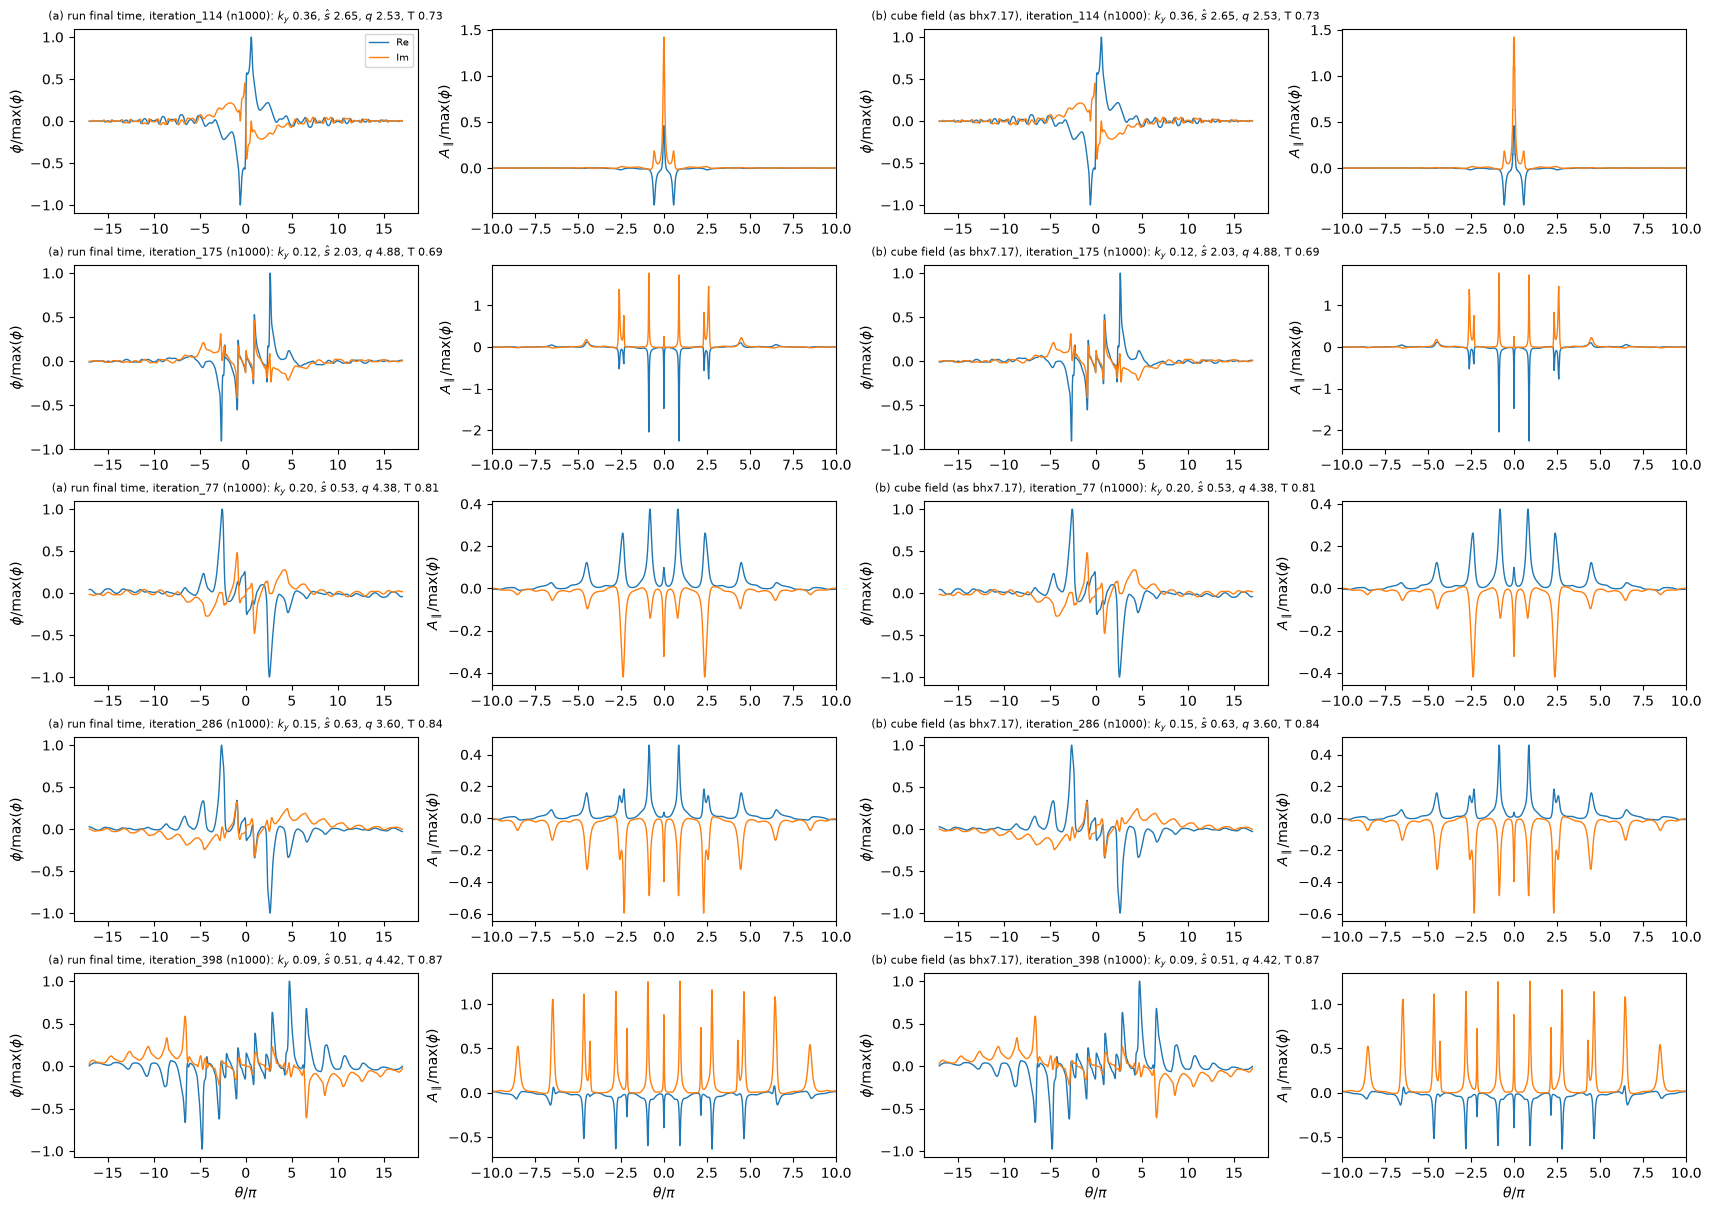

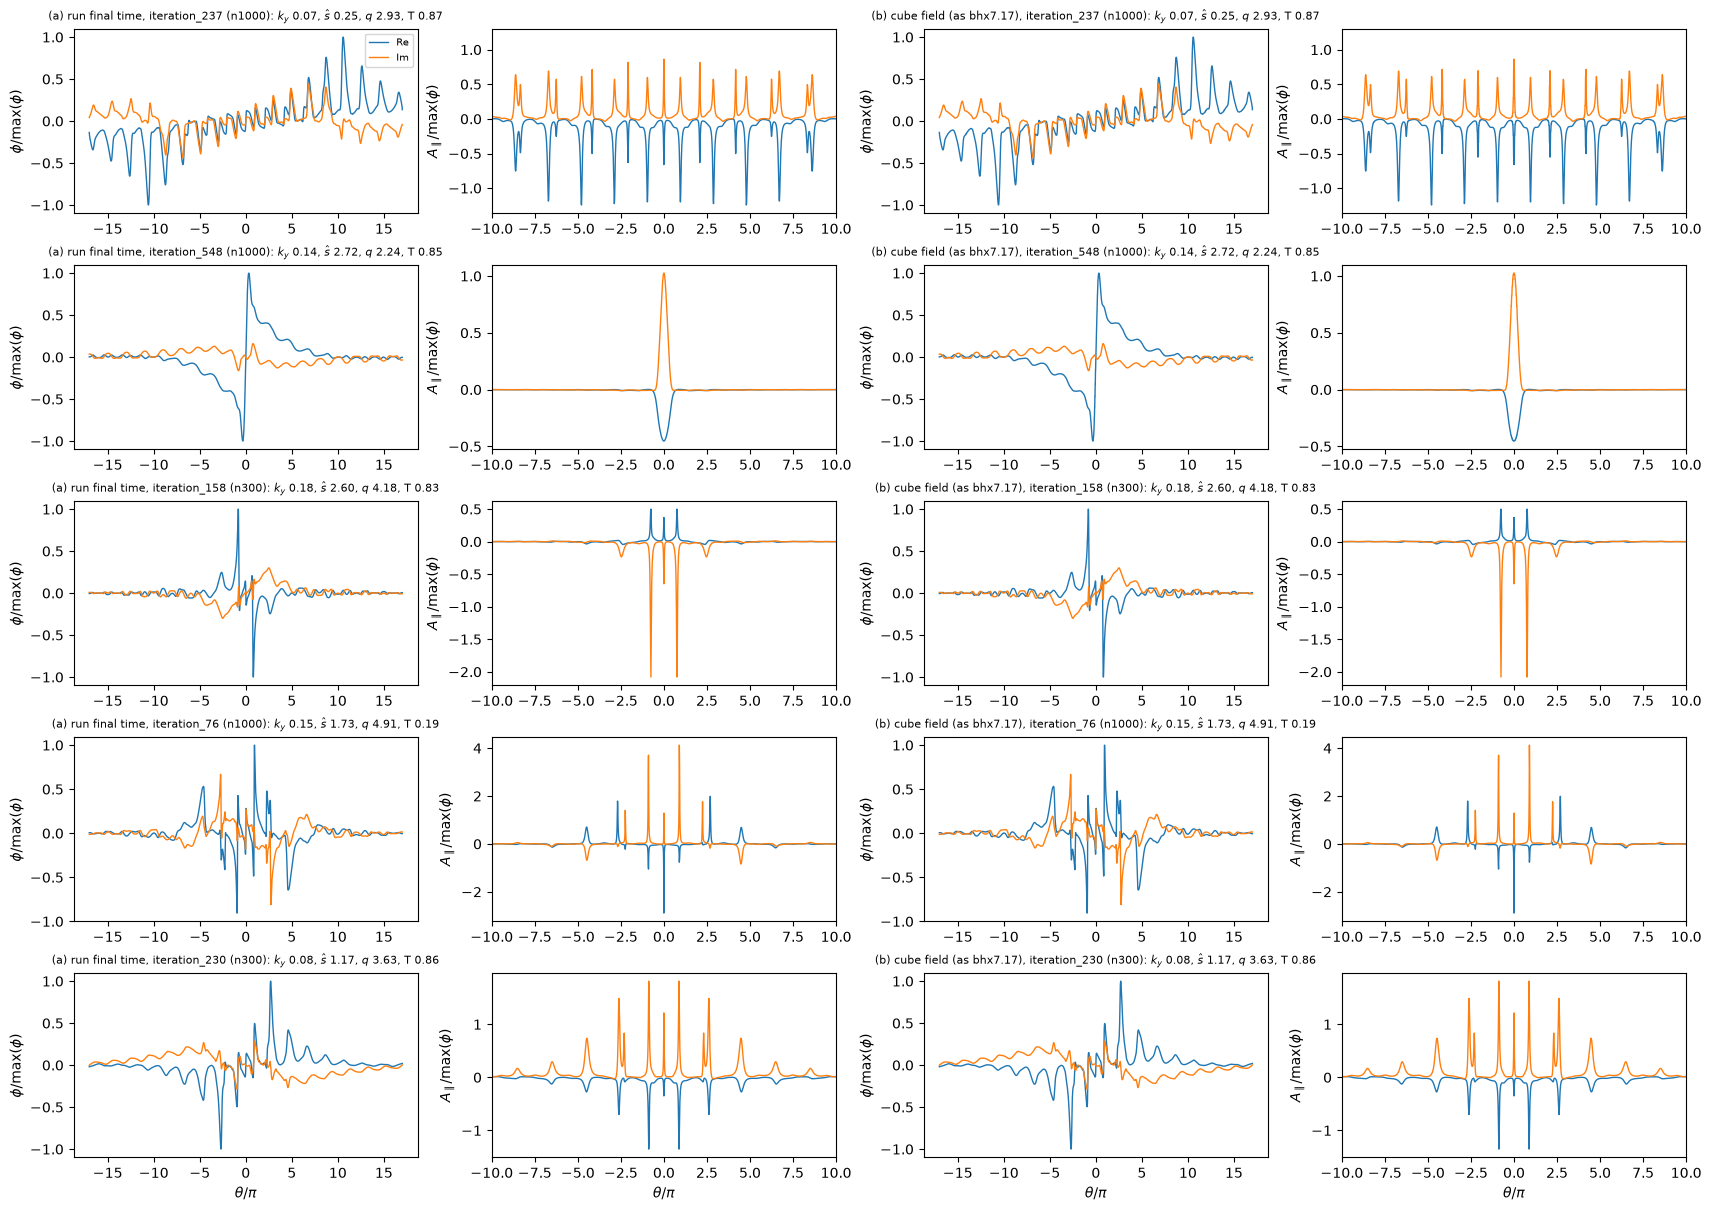

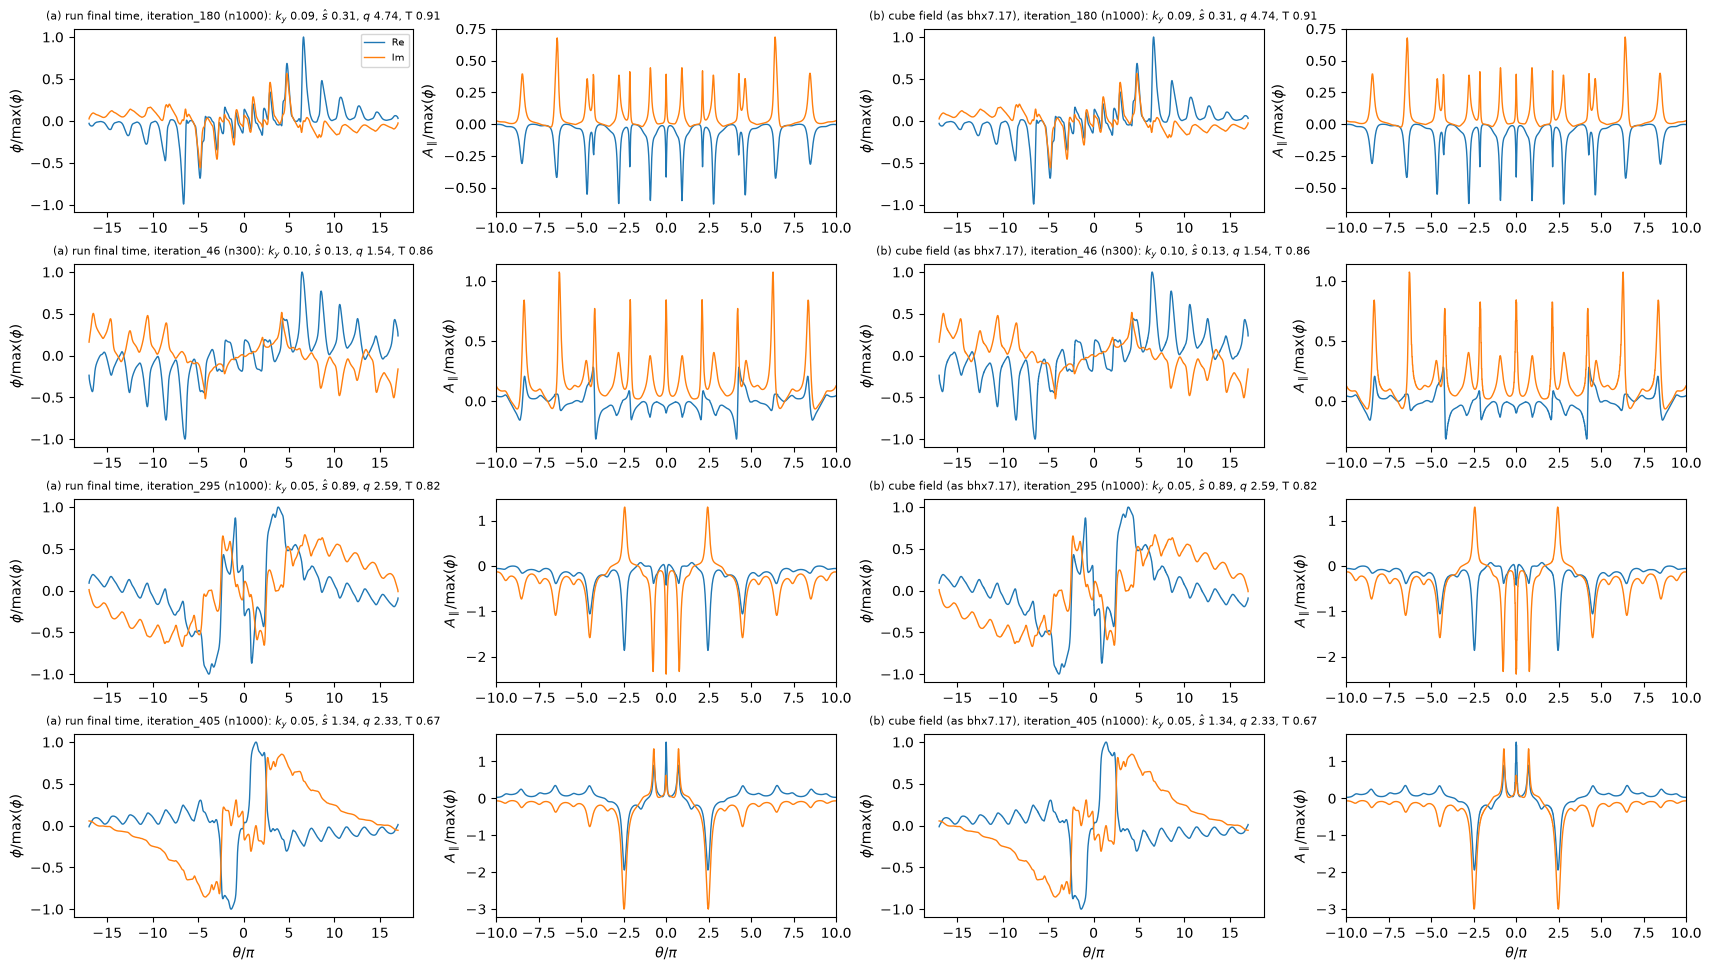

In [5]:
def draw_pair(axes_pair, theta, field_values, title):
    scale = np.abs(field_values["phi"]).max()
    reference = field_values["phi"][np.argmax(np.abs(field_values["phi"]))]
    for ax, field, window, label in zip(axes_pair, fields, ((-1, 1), (-10, 10)), (r"$\phi/\max(\phi)$", r"$A_\parallel/\max(\phi)$")):
        values = rotated(field_values[field], reference) / scale
        ax.plot(theta / np.pi, values.real, color="C0", lw=1, marker="", label="Re")
        ax.plot(theta / np.pi, values.imag, color="C1", lw=1, marker="", label="Im")
        if window[0] == -10:
            ax.set_xlim(-10, 10)
        ax.set(ylabel=label)
    axes_pair[0].set_title(title, fontsize=8)


per_figure = 5
for figure_number, start in enumerate(range(0, len(chosen), per_figure)):
    group = chosen[start:start + per_figure]
    fig, axes = plt.subplots(len(group), 4, figsize=(17, 2.4 * len(group)), constrained_layout=True, squeeze=False)
    for row_axes, key in zip(axes, group):
        info = report[(report.draw == key[0]) & (report["sample"] == key[1])].iloc[0]
        label = (f"{key[1]} ({key[0]}): $k_y$ {info.ky:.2f}, $\\hat s$ {info.shat:.2f}, $q$ {info.q:.2f}, T {info["T"]:.2f}")
        draw_pair(row_axes[:2], curves[key]["theta"], curves[key]["final"], "(a) run final time, " + label)
        draw_pair(row_axes[2:], curves[key]["theta"], curves[key]["cube"], "(b) cube field (as bhx7.17), " + label)
    axes[0, 0].legend(fontsize=7)
    for ax in axes[-1]:
        ax.set_xlabel(r"$\theta/\pi$")
    fig.savefig(plots_dir / f"gs2_mtm_phi_and_apar_vs_theta_run_cube_{figure_number}.png", dpi=130)
    plt.show()

## Tail average against final time, and $|f|^2$ in $\theta$ against $\theta_b$ (checks (i), (ii))
$|A_\parallel|^2/\max$: final time (solid), average over pyro's $\gamma$-tolerance window, the last 20 % of the run, of each time's
normalised $|A_\parallel|^2$ (dashed) against $\theta/\pi$ (left) and $\theta_b/\pi$ (right). A relabelling of the axis should leave the spike
train the same.

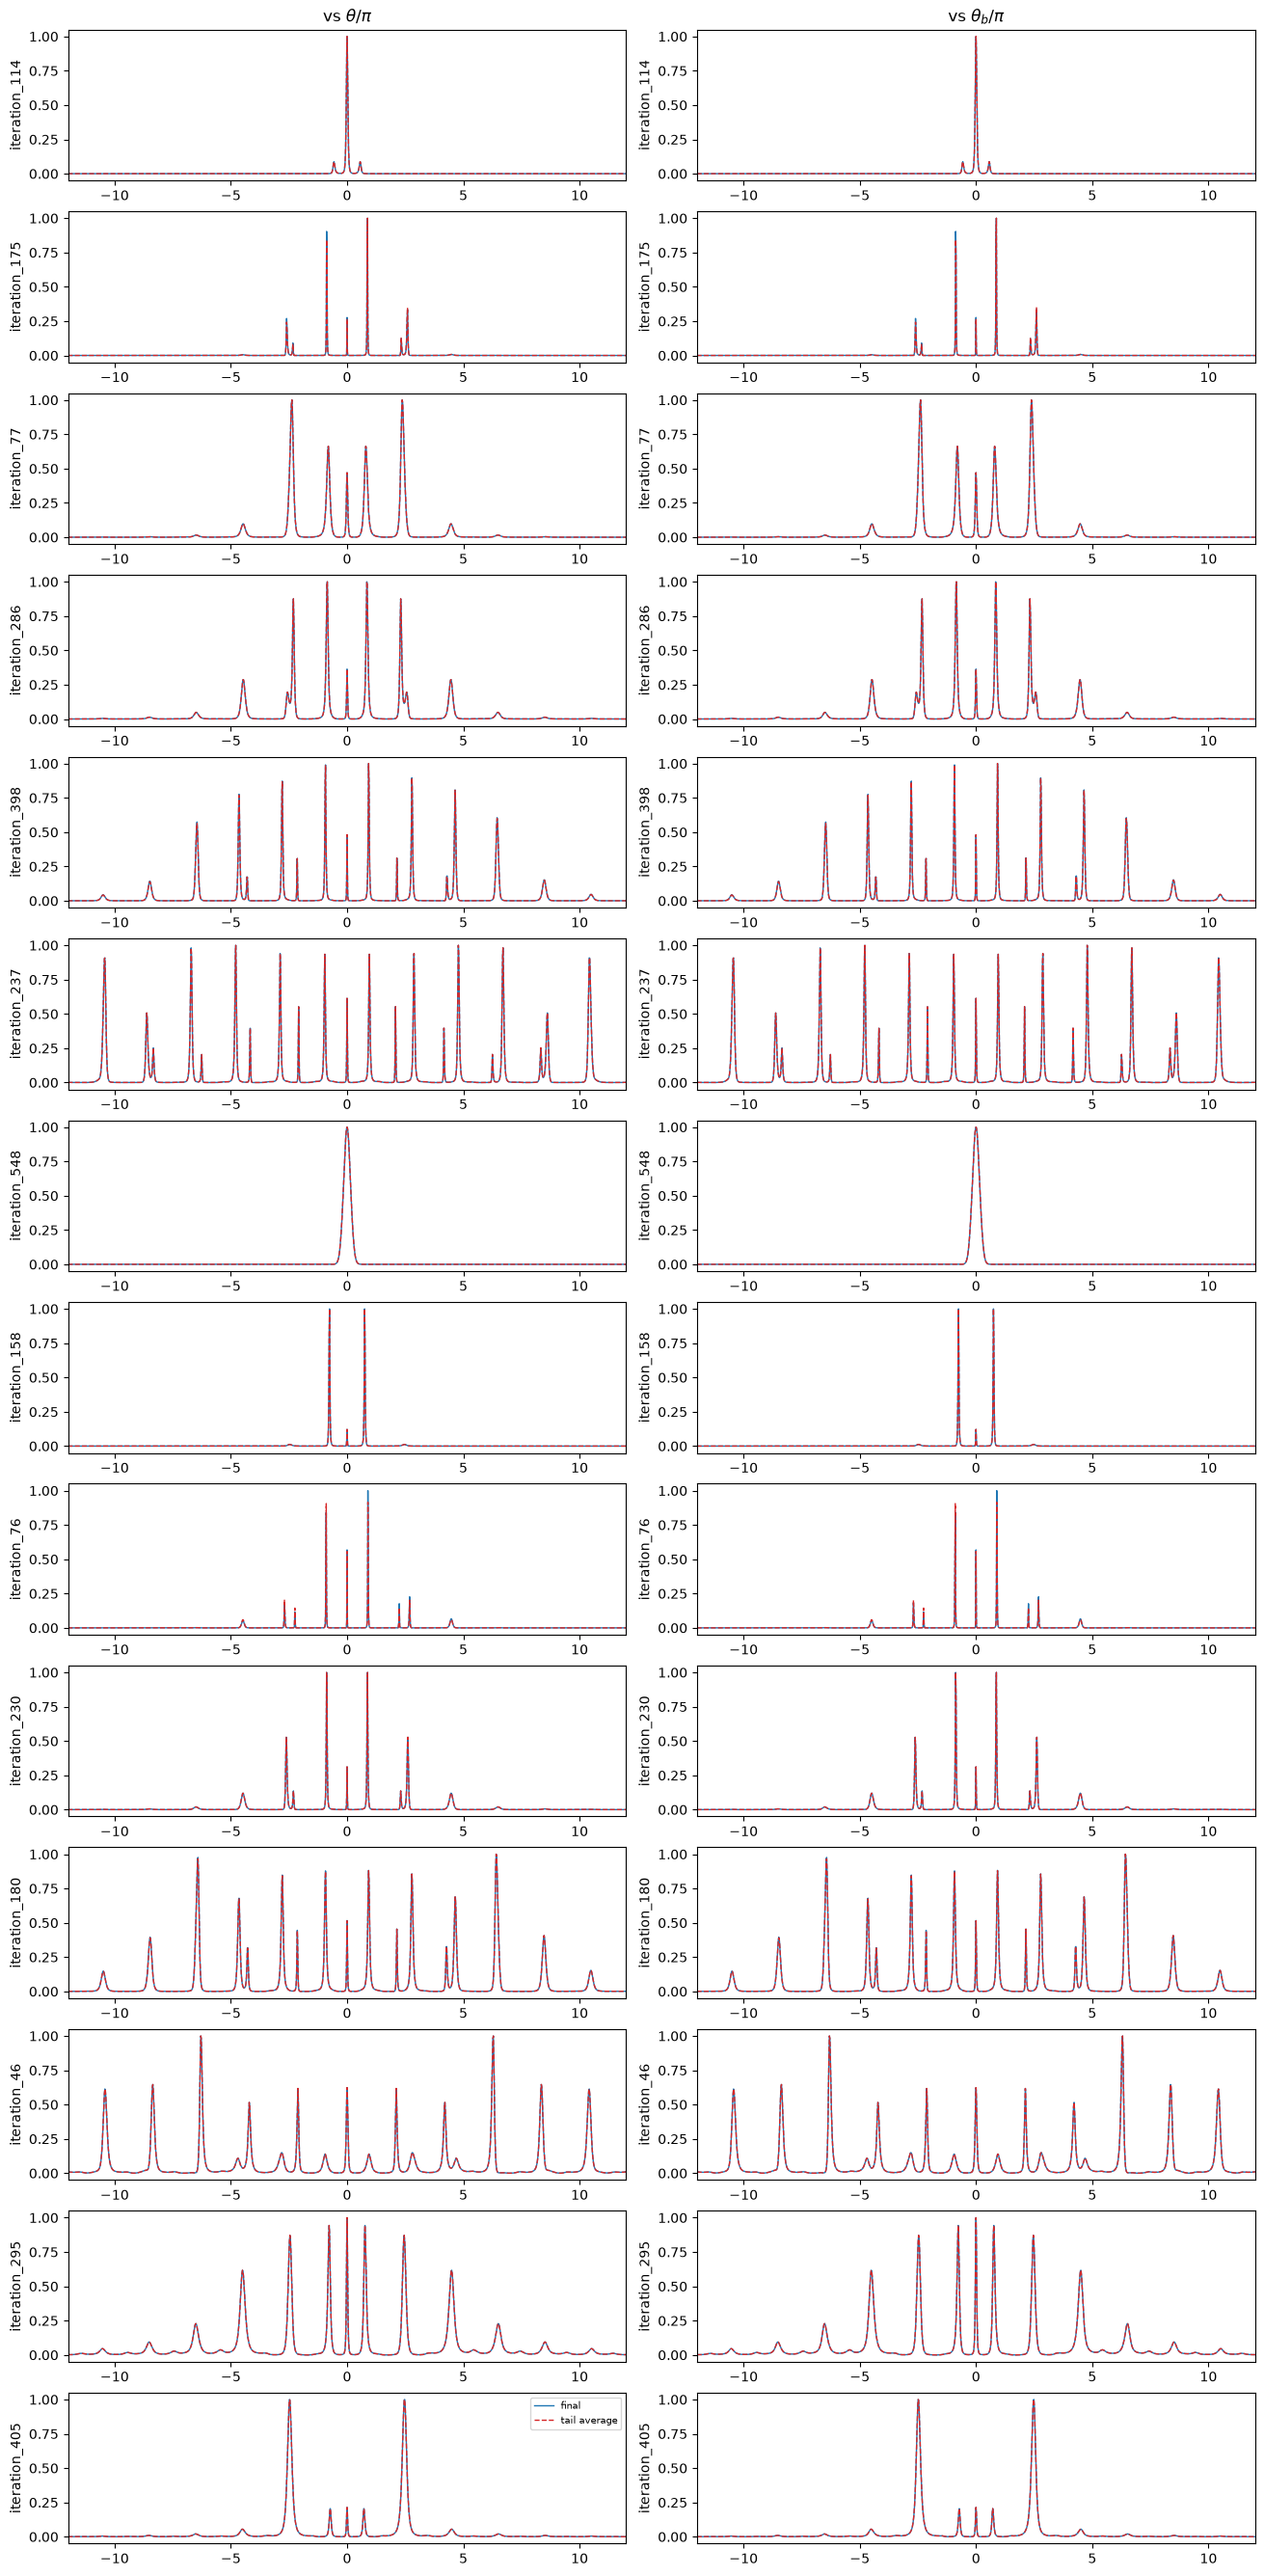

In [6]:
fig, axes = plt.subplots(len(chosen), 2, figsize=(13, 1.9 * len(chosen)), constrained_layout=True, squeeze=False)
for row_axes, key in zip(axes, chosen):
    for ax, axis_name in zip(row_axes, ("theta", "basis_angle")):
        coordinate = curves[key][axis_name] / np.pi
        power = np.abs(curves[key]["final"]["apar"]) ** 2
        ax.plot(coordinate, power / power.max(), color="C0", lw=1, marker="", label="final")
        ax.plot(coordinate, curves[key]["tail_power"]["apar"], color="C3", lw=1, ls="--", marker="", label="tail average")
        ax.set(xlim=(-12, 12), ylabel=key[1])
row_axes[0].legend(fontsize=7)
axes[0, 0].set_title(r"vs $\theta/\pi$"); axes[0, 1].set_title(r"vs $\theta_b/\pi$")
fig.savefig(plots_dir / "gs2_mtm_apar_power_vs_theta_basis_angle_per_time_average.png", dpi=130)
plt.show()